# Beyond averages: three research extensions for SHA

These exploratory analyses complement, rather than replace, the original notebook. Run all cells from top to bottom. The questions were selected after inspecting the data: the intervals below are exploratory uncertainty summaries, not confirmatory tests or causal evidence.

**Measurement warning:** all records mark `timing_semantics_verified=false`. Use **recorded timestamp gap**, not verified operational delay. Operating-carrier identity is unavailable. The dataset covers one airport and only 31 dates; records are not established to be a complete census.

## Questions
1. How often does a departure timestamp at least 15 minutes after schedule accompany an arrival timestamp less than 15 minutes after schedule?
2. Can evening departures have a smaller typical gap but a larger extreme-tail risk, even within the same route and date?
3. Are cancellations spread evenly through the month, or concentrated on a few dates? Does the calendar comparison justify a holiday explanation?


In [1]:
from pathlib import Path
from html import escape
from IPython.display import HTML, display
import matplotlib.pyplot as plt
from scripts.explore_research import analyze

root = Path.cwd()
if not (root / 'sha_master.csv').exists():
    raise FileNotFoundError('Run this notebook with the project root as its working directory.')
results = analyze(root / 'sha_master.csv')
audit = results['audit']
print(audit)
assert audit['rows'] == sum(audit['directions'].values())
assert sum(day['known'] for day in results['cancellations']['daily']) == audit['rows'] - audit['unknown_status']
assert sum(day['canceled'] for day in results['cancellations']['daily']) == audit['canceled']

def table(headers, rows):
    heading = ''.join(f'<th>{escape(str(value))}</th>' for value in headers)
    body = ''.join('<tr>' + ''.join(f'<td>{escape(str(value))}</td>' for value in row) + '</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table>'))


{'rows': 23705, 'dates': 31, 'date_range': ['2026-09-22', '2026-10-22'], 'directions': {'arrival': 11873, 'departure': 11832}, 'unknown_status': 34, 'canceled': 487, 'timing_semantics_verified': {'false': 23705}, 'operating_carrier_nonempty': 0, 'eligible_departures': 11560, 'exclusions': {'arrival_unknown_or_canceled': 259, 'departure_unknown_or_canceled': 262, 'departure_missing_paired_timestamp': 19, 'arrival_missing_paired_timestamp': 15, 'departure_missing_departure_timestamp': 10}}


## 1. The paired-timestamp paradox

For each known, noncanceled record with all four timestamps, calculate departure gap = actual departure minus scheduled departure; arrival gap = recorded landing minus scheduled arrival. Treat SHA arrivals and SHA departures as **separate cohorts**, since the endpoints differ.

The paired quantity departure gap minus arrival gap equals scheduled duration minus recorded elapsed duration. This is an arithmetic identity, **not independent evidence of airborne recovery**. Gate-to-gate schedule versus takeoff/landing observations, schedule buffers, or other event-definition differences could explain it. Aircraft speed, deliberate schedule padding, and pilot action cannot be inferred.

The conditional fraction below asks how many records with departure gap >=15 have arrival gap <15. It does **not** require an early arrival. Intervals resample whole SHA local service dates, 2,000 times, seed 20261024. Arrival cohorts are clustered by their SHA arrival date, not necessarily their origin departure date.


Cohort,Paired n,Median departure gap (min),Median arrival gap (min),Median paired reduction (min),Conditional numerator/denominator,Conditional % [95% date-bootstrap interval]
SHA arrivals,11599,13.35,-15.47,29.68,4125/5096,"80.95% [78.46, 83.66]"
SHA departures,11551,17.30,-8.97,27.32,5721/6923,"82.64% [78.68, 86.37]"


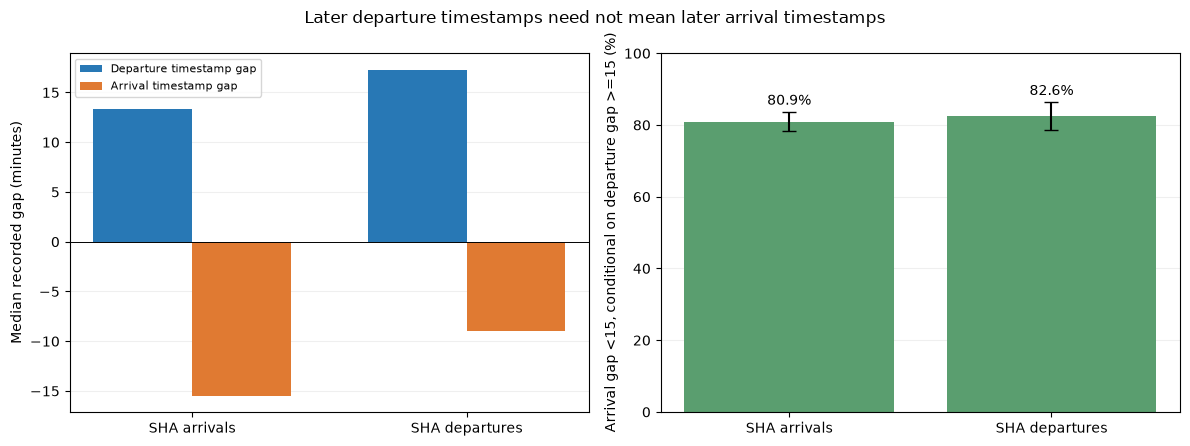

In [2]:
paired = results['paired_timestamps']
rows = []
for direction in ('arrival', 'departure'):
    summary = paired[direction]
    low, high = summary['arrival_lt15_among_departure_ge15_date_bootstrap_ci_pct']
    rows.append([
        f'SHA {direction}s', summary['n'],
        f"{summary['departure']['median']:.2f}",
        f"{summary['arrival']['median']:.2f}",
        f"{summary['scheduled_duration_minus_recorded_elapsed_minutes']['median']:.2f}",
        f"{summary['arrival_lt15_among_departure_ge15_n']}/{summary['departure_ge15_n']}",
        f"{summary['arrival_lt15_among_departure_ge15_pct']:.2f}% [{low:.2f}, {high:.2f}]",
    ])
table(['Cohort', 'Paired n', 'Median departure gap (min)', 'Median arrival gap (min)', 'Median paired reduction (min)', 'Conditional numerator/denominator', 'Conditional % [95% date-bootstrap interval]'], rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for position, direction in enumerate(('arrival', 'departure')):
    summary = paired[direction]
    axes[0].bar(position - 0.18, summary['departure']['median'], width=0.36, color='#2878B5', label='Departure timestamp gap' if position == 0 else None)
    axes[0].bar(position + 0.18, summary['arrival']['median'], width=0.36, color='#E07A32', label='Arrival timestamp gap' if position == 0 else None)
    value = summary['arrival_lt15_among_departure_ge15_pct']
    low, high = summary['arrival_lt15_among_departure_ge15_date_bootstrap_ci_pct']
    axes[1].bar(position, value, color='#5A9E6F')
    axes[1].errorbar(position, value, yerr=[[value-low], [high-value]], color='black', capsize=5)
    axes[1].text(position, high + 2, f'{value:.1f}%', ha='center')
for ax in axes:
    ax.set_xticks([0, 1], ['SHA arrivals', 'SHA departures'])
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
axes[0].axhline(0, color='black', linewidth=0.7)
axes[0].set_ylabel('Median recorded gap (minutes)')
axes[0].legend(fontsize=8)
axes[1].set_ylim(0, 100)
axes[1].set_ylabel('Arrival gap <15, conditional on departure gap >=15 (%)')
fig.suptitle('Later departure timestamps need not mean later arrival timestamps')
fig.tight_layout()
plt.show()


### Robustness: identity flags and routes

Exclude records flagged in either identity-review field. Also examine route-level medians with at least 100 paired records. These checks describe sensitivity and heterogeneity; they do not validate timestamp meanings. Route thresholds were chosen for exploratory reporting, not to establish significance.


In [3]:
rows = []
for direction, summary in paired.items():
    clean = summary['excluding_identity_review']
    routes = summary['routes_n_ge100']
    positive = sum(route['median_gain'] > 0 for route in routes)
    rows.append([direction, summary['n'], clean['n'],
        f"{summary['arrival_lt15_among_departure_ge15_pct']:.2f}%",
        f"{clean['arrival_lt15_among_departure_ge15_pct']:.2f}%",
        f'{positive}/{len(routes)}'])
table(['Cohort', 'All paired n', 'Unflagged n', 'Conditional % all', 'Conditional % unflagged', 'Routes with positive median reduction / routes n>=100'], rows)


Cohort,All paired n,Unflagged n,Conditional % all,Conditional % unflagged,Routes with positive median reduction / routes n>=100
arrival,11599,11579,80.95%,80.93%,31/31
departure,11551,11527,82.64%,82.66%,31/31


## 2. Typical experience versus extreme-tail risk

Use the original notebook's windows: morning 06:00-11:59 and evening 17:00-22:59 Shanghai time. An extreme gap is defined here as >=60 minutes. This threshold and the question are exploratory, not a regulatory definition.

First compare the median, 95th percentile and >=60-minute fraction. Then compare morning and evening **within the same route and local date**, including cells with at least one record per window. Average contrasts equally across route-date cells, rather than across flights. Date-cluster resampling preserves dependence within each date. The matched estimand differs from both the pooled comparison and the original notebook's route-weekday comparison.

Report both the mean-gap contrast and the extreme-risk contrast, including intervals that cross zero. Repeat using at least two records per window and omit each date in turn to check single-date sensitivity.


Window,n,Mean (min),Median (min),95th percentile (min),Gap >=60 (%)
morning,4531,21.69,18.88,44.18,2.43
evening,3406,22.85,15.96,72.73,6.84


Matched cells: 860; records: 6948; dates: 31
Evening minus morning, mean_difference: +0.52 minutes; 95% date-bootstrap interval [-2.31, +4.71]
Evening minus morning, ge60_difference_pp: +3.60 percentage points; 95% date-bootstrap interval [+0.96, +7.74]
Sensitivity, minimum two records in EACH window: {'mean_difference': {'cells': 644, 'dates': 31, 'estimate': 0.5043916915986015, 'date_bootstrap_ci': [-2.49105002766663, 4.80995563753104]}, 'ge60_difference_pp': {'cells': 644, 'dates': 31, 'estimate': 3.862175609070019, 'date_bootstrap_ci': [0.9251283623951958, 8.21052001852154]}}
Extreme-risk difference range omitting each date: [1.7868326151639475, 3.9343869271753884]


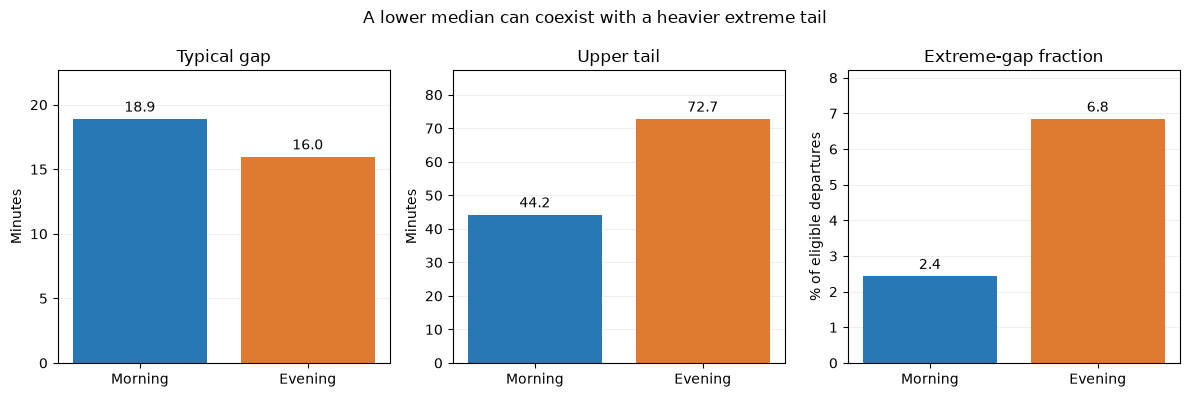

In [4]:
tail = results['morning_evening_tail']
table(['Window', 'n', 'Mean (min)', 'Median (min)', '95th percentile (min)', 'Gap >=60 (%)'], [
    [window, tail[window]['n']] + [f'{tail[window][key]:.2f}' for key in ('mean', 'median', 'p95', 'ge60_pct')]
    for window in ('morning', 'evening')])
print(f"Matched cells: {tail['matched_route_date_cells']}; records: {tail['matched_records']}; dates: {tail['matched_dates']}")
for metric, units in (('mean_difference', 'minutes'), ('ge60_difference_pp', 'percentage points')):
    point = tail['matched_' + metric]
    low, high = tail['matched_' + metric + '_date_bootstrap_ci']
    print(f'Evening minus morning, {metric}: {point:+.2f} {units}; 95% date-bootstrap interval [{low:+.2f}, {high:+.2f}]')
print('Sensitivity, minimum two records in EACH window:', tail['sensitivity_min2_per_window'])
print('Extreme-risk difference range omitting each date:', tail['ge60_difference_pp_leave_one_date_out_range'])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric, title, units in zip(axes, ('median', 'p95', 'ge60_pct'), ('Typical gap', 'Upper tail', 'Extreme-gap fraction'), ('Minutes', 'Minutes', '% of eligible departures')):
    values = [tail[window][metric] for window in ('morning', 'evening')]
    bars = ax.bar(['Morning', 'Evening'], values, color=['#2878B5', '#E07A32'])
    ax.bar_label(bars, fmt='%.1f', padding=3)
    ax.set_ylim(0, max(values) * 1.2)
    ax.set_title(title)
    ax.set_ylabel(units)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle('A lower median can coexist with a heavier extreme tail')
fig.tight_layout()
plt.show()


## 3. Cancellation concentration, not a holiday causal claim

The denominator is **known-status records**, including cancellations; unknown/blank statuses are excluded. Combine arrival and departure event records only for this airport-event description, not as independent passenger experiences. A disruption can affect multiple related events.

Select the five dates with the largest cancellation counts and compare their share of cancellations with their share of known records. This is a **post-hoc concentration statistic**: it deliberately picks the largest dates and must not be interpreted as a prospective risk rule or a statistical test.

For calendar categories, show the number of dates as well as records. The adjusted-workday category has only one date, so it cannot support a general workday conclusion. Public-holiday versus ordinary-weekday comparisons are observational, have overlapping date-bootstrap intervals, and cannot separate holidays from other date-specific conditions. Do not claim that holidays cause cancellations or that overlapping intervals prove no difference.


Date,Canceled,Known statuses,Cancellation %
2026-09-29,62,761,8.15
2026-09-28,46,751,6.13
2026-09-26,45,721,6.24
2026-10-08,42,769,5.46
2026-10-03,37,748,4.95


Top five dates: 47.64% of cancellations vs 15.84% of known records.
Cancellation rate on those dates: 6.19%; other dates: 1.28%.


Calendar category,Dates,Known,Canceled,Cancellation %,95% date-bootstrap interval (%)
adjusted_workday,1,680,30,4.41,Not estimable from one date
ordinary_weekday,17,13089,253,1.93,"0.94, 3.08"
public_holiday,10,7634,185,2.42,"1.32, 3.69"
weekend,3,2268,19,0.84,"0.00, 1.54"


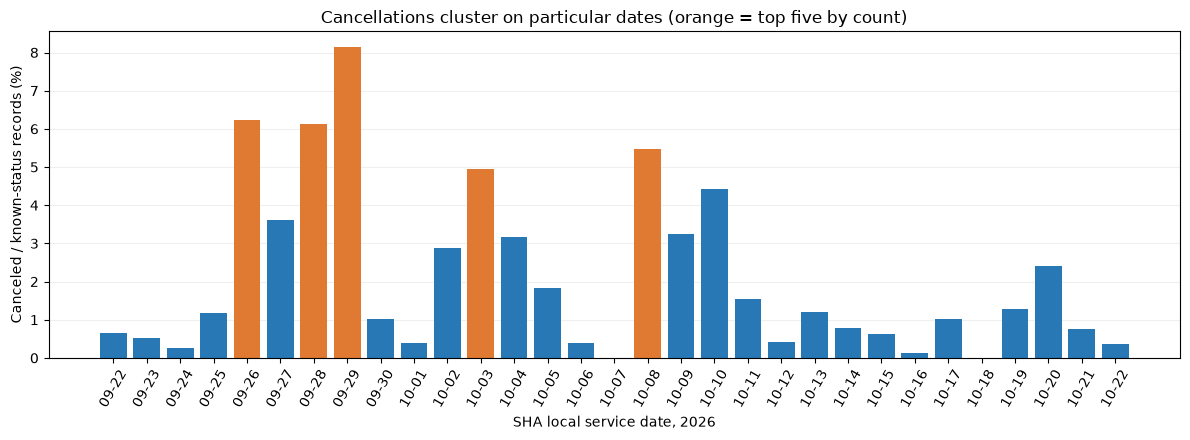

In [5]:
cancellations = results['cancellations']
top = cancellations['top5_dates']
table(['Date', 'Canceled', 'Known statuses', 'Cancellation %'], [
    [day['date'], day['canceled'], day['known'], f"{day['canceled_pct']:.2f}"] for day in top])
print(f"Top five dates: {cancellations['top5_dates_share_of_cancellations_pct']:.2f}% of cancellations vs {cancellations['top5_dates_share_of_known_records_pct']:.2f}% of known records.")
print(f"Cancellation rate on those dates: {cancellations['top5_dates_cancellation_pct']:.2f}%; other dates: {cancellations['remaining_dates_cancellation_pct']:.2f}%.")
table(['Calendar category', 'Dates', 'Known', 'Canceled', 'Cancellation %', '95% date-bootstrap interval (%)'], [
    [group['category'], group['dates'], group['known'], group['canceled'], f"{group['canceled_pct']:.2f}",
     'Not estimable from one date' if group['date_bootstrap_ci_pct'] is None else ', '.join(f'{value:.2f}' for value in group['date_bootstrap_ci_pct'])]
    for group in cancellations['calendar']])

daily = cancellations['daily']
top_dates = {day['date'] for day in top}
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(range(len(daily)), [day['canceled_pct'] for day in daily], color=['#E07A32' if day['date'] in top_dates else '#2878B5' for day in daily])
ax.set_xticks(range(len(daily)), [day['date'][5:] for day in daily], rotation=60)
ax.set_ylabel('Canceled / known-status records (%)')
ax.set_xlabel('SHA local service date, 2026')
ax.set_title('Cancellations cluster on particular dates (orange = top five by count)')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


## Suggested presentation argument

**Title:** *Beyond averages: timestamp-gap reduction, extreme-tail risk, and cancellation concentration at Shanghai Hongqiao.*

1. Explain the sample, missingness and event-semantics warning before showing outcomes.
2. Present the paired departure/arrival paradox as a measurement-aware descriptive finding, not proof that aircraft made up time.
3. Show why the median and extreme-tail risk answer different passenger questions. Include both matched estimates and their intervals; do not hide the near-zero mean contrast.
4. Show cancellation concentration, then explain why a calendar-only story is too strong.
5. Conclude with what additional evidence is needed: validated event definitions, coverage checks, a longer observation period, weather/ATC information, and verified operating-carrier identities.

**Research integrity:** these questions were discovered in this file. Replication on a separate month would be stronger than adding more exploratory significance tests. No result or analysis can guarantee a particular course grade; align the final scope with the instructor's rubric and any proposal-approval requirements.
